In [5]:
import surpRISe
print(f"Versión de la librería: {surpRISe.__version__ if hasattr(surpRISe, '__version__') else 'Cargada correctamente'}")

Versión de la librería: Cargada correctamente


In [6]:
# %matplotlib widget

import numpy as np
import plotly.io as pio
from scipy.constants import c, pi

pio.renderers.default = (
    "notebook_connected"  # 'browser' for avoid error but shown in the browser
)

# import surpRISe
from surpRISe.channels.tx2ris2rx.tang_general_channel import tang_general_channel
from surpRISe.components.antenna import Antenna
from surpRISe.components.ris import RIS
from surpRISe.utils.utils import *

In [7]:
# Create RIS
f = 28e9
lam = c / f

ris = RIS(
    center=[0, 0, 0],
    boresight="z",
    Ncol=32,
    Nrow=32,
    delta_h=lam / 2,
    delta_v=lam / 2,
    dx=0.47 * lam,
    dy=0.47 * lam,
    fc=f,
    radiation_factor=1,
    phase_shifts_dict={"0": 0, "1": pi},
    att_dict={"0": 1, "1": 1},
)

# Create channel
channel = tang_general_channel()

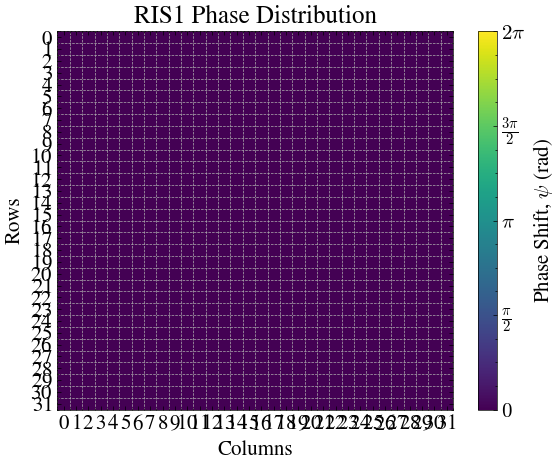

[[ 1.00712764e-05+1.75136481e-06j  9.84420257e-06-2.72934422e-06j
   7.72107697e-06-6.67814600e-06j]
 [-7.24370366e-09-2.41726769e-08j  4.41751830e-08+6.38782127e-07j
  -7.66177471e-07-1.36310633e-07j]
 [-4.88158732e-07+1.09193085e-07j  1.11912187e-08-4.56770243e-07j
  -2.12184610e-07-3.91517145e-08j]]
[[1.04497887e-10 1.04357644e-10 1.04212664e-10]
 [6.36789553e-16 4.09994052e-13 6.05608505e-13]
 [2.50222077e-13 2.08764299e-13 4.65551654e-14]]
[[1.04497887e-10 1.04357644e-10 1.04212664e-10]
 [6.36789553e-16 4.09994052e-13 6.05608505e-13]
 [2.50222077e-13 2.08764299e-13 4.65551654e-14]]
[[ -99.8089249   -99.81475734  -99.82079504]
 [-151.9600407  -123.87222444 -122.17808034]
 [-126.01674375 -126.80343769 -133.32032126]]


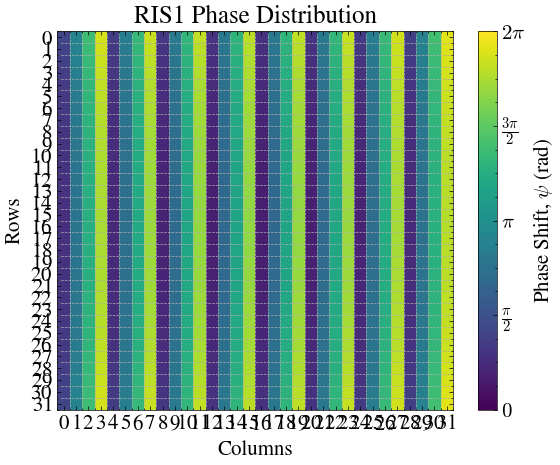

[[-7.74214856e-10+1.39460071e-09j -1.65675702e-10+1.27340047e-09j
   1.98083115e-10+9.64058090e-10j]
 [ 1.92023296e-05-1.35046458e-17j -3.75763871e-06+1.63004681e-05j
  -9.35620545e-06-4.61974248e-06j]
 [-1.41202985e-06-7.67026121e-08j  3.17079955e-07-1.13386114e-06j
  -4.56843106e-07-2.35879317e-07j]]
[[2.54431980e-18 1.64899719e-18 9.68644921e-19]
 [3.68729463e-10 2.79825109e-10 1.08880601e-10]
 [1.99971159e-12 1.38618078e-12 2.64344676e-13]]
[[2.54431980e-18 1.64899719e-18 9.68644921e-19]
 [3.68729463e-10 2.79825109e-10 1.08880601e-10]
 [1.99971159e-12 1.38618078e-12 2.64344676e-13]]
[[-175.94428303 -177.82780083 -180.13835394]
 [ -94.33292159  -95.53113319  -99.63049491]
 [-116.99032636 -118.58180127 -125.77829432]]


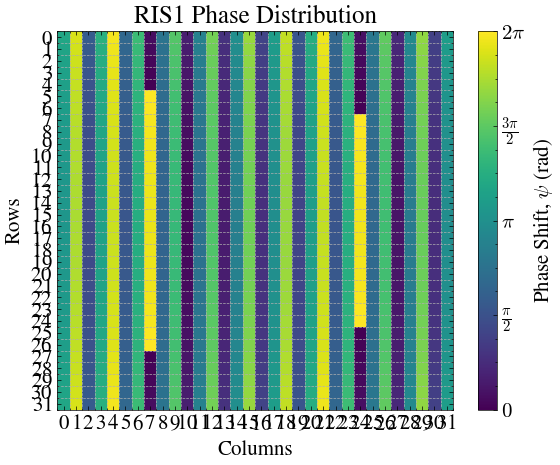

[[-2.95509699e-07-4.91614826e-08j -2.87456558e-07+8.44410560e-08j
  -2.22017106e-07+2.01213182e-07j]
 [-1.56250941e-06+8.72547042e-08j  1.43150779e-08-1.79914164e-07j
  -1.51171270e-06-6.19609128e-07j]
 [ 1.73515285e-05-1.20430830e-17j -2.97606323e-06+1.27130085e-05j
  -3.43566326e-06-1.80687931e-06j]]
[[8.97428335e-14 8.97615644e-14 8.97783401e-14]
 [2.44904903e-12 3.25740277e-14 2.66919076e-12]
 [3.01075540e-10 1.70477539e-10 1.50685949e-11]]
[[8.97428335e-14 8.97615644e-14 8.97783401e-14]
 [2.44904903e-12 3.25740277e-14 2.66919076e-12]
 [3.01075540e-10 1.70477539e-10 1.50685949e-11]]
[[-130.47000222 -130.46909587 -130.46828428]
 [-116.11002521 -134.87128539 -115.73620388]
 [ -95.21324526  -97.68332834 -108.21927244]]


In [8]:
# Create antennas and channel
tx_pos = sph2cart([10, 0, 0])
tx_antenna = Antenna(tx_pos, 0)

rx_pos1 = sph2cart([10, 180, 30])
rx_antenna1 = Antenna(rx_pos1, 0)

rx_pos2 = sph2cart([10, 180, 45])
rx_antenna2 = Antenna(rx_pos2, 0)

rx_pos = np.array([[0, 0, 20], rx_pos1[0], rx_pos2[0]])

# Generate rx locations as a 2D map
ris.reset_ris()
ris.plot_phase_dist()
res = channel.channel_matrix_multrx(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, rx_positions=rx_pos, ris=ris, f_vector=[ris.fc, 29e9, 30e9])
print(
    res
)

print(
    np.abs(res) ** 2
)

print(
    channel.path_gain_multrx(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, rx_positions=rx_pos, ris=ris, f_vector=[ris.fc, 29e9, 30e9])
)

print(20*np.log10(np.abs(res)))

channel.optimize(
    optimizer="direct_disc",
    mode="cont",
    wave_model="spherical",
    tx_antenna=tx_antenna,
    rx_antenna=rx_antenna1,
    ris=ris,
)
ris.plot_phase_dist()
res = channel.channel_matrix_multrx(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, rx_positions=rx_pos, ris=ris, f_vector=[ris.fc, 29e9, 30e9])
print(
    res
)

print(
    np.abs(res) ** 2
)

print(
    channel.path_gain_multrx(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, rx_positions=rx_pos, ris=ris, f_vector=[ris.fc, 29e9, 30e9])
)

print(20*np.log10(np.abs(res)))


channel.optimize(
    optimizer="direct_disc",
    mode="cont",
    wave_model="spherical",
    tx_antenna=tx_antenna,
    rx_antenna=rx_antenna2,
    ris=ris,
)
ris.plot_phase_dist()
res = channel.channel_matrix_multrx(tx_antenna=tx_antenna, rx_antenna=rx_antenna2, rx_positions=rx_pos, ris=ris, f_vector=[ris.fc, 29e9, 30e9])
print(
    res
)

print(
    np.abs(res) ** 2
)

print(
    channel.path_gain_multrx(tx_antenna=tx_antenna, rx_antenna=rx_antenna2, rx_positions=rx_pos, ris=ris, f_vector=[ris.fc, 29e9, 30e9])
)

print(20*np.log10(np.abs(res)))
